# SaaS Customer Churn & Retention Analysis


## 1. Project Introduction

### Project Overview
Customer churn is a major challenge for Software as a Service (SaaS) businesses. When customers stop using a service, businesses may lose recurring revenue and future growth opportunities.

This project analyses customer data to understand churn patterns, identify possible risk factors, and discover opportunities to improve customer retention.

### Project Objectives
- Analyse customer demographics and company characteristics.
- Understand customer churn patterns.
- Investigate the relationship between feature adoption and customer churn.
- Evaluate payment status, subscription plans and customer activity.
- Analyse recurring revenue and customer retention.
- Identify potential factors associated with customer churn.
- Develop data-driven business recommendations.

### Dataset Description
- Dataset: SaaS Customer Churn Dataset
- Total records: 50,000 customers
- Original columns: 18
- Data type: Synthetic customer data
- Tools: Python, Pandas, NumPy, Matplotlib and Seaborn.

### Project Workflow
1. Data Loading
2. Data Understanding
3. Data Quality Assessment
4. Data Cleaning and Preparation
5. Exploratory Data Analysis (EDA)
6. Categorical and Text-Based Analysis
7. Customer Churn Analysis
8. Revenue Analysis
9. Data Visualisation
10. Business Insights and Recommendations

### Expected Outcome
The project aims to identify meaningful patterns in customer behaviour and provide actionable recommendations that could help a SaaS business improve customer retention and understand revenue risks.

**Note:** This project uses synthetic data for educational and analytical purposes. Findings should not be interpreted as actual company performance or industry benchmarks.



### 2. Data Loading and Initial Inspection

**Purpose:** Import the required Python libraries, load the SaaS customer dataset into a Pandas DataFrame, verify that it has loaded successfully, check its dimensions and preview the first five records.

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/MP_Synthetics_50000_Rows.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (50000, 18)


,Customer_ID,Company_Name,Industry,Country,Company_Size,Account_Manager,Plan_Tier,Billing_Cycle,Monthly_Recurring_Revenue,Signup_Date,Last_Active_Date,Payment_Status,Active_Seats_Used,Total_Seats_Allowed,Support_Tickets_30d,Feature_Adoption_Rate,Churn_Risk_Score,Is_Churned
0,CUST-1001,Pulse Net 944,HealthTech,Australia,11-50,Sarah Jenkins,Starter,Annual,49,2025-03-12,2026-02-18,Active,3,8,5,44%,Low,0
1,CUST-1002,Pulse Logic 332,CyberSecurity,USA,51-200,David Ross,Pro,Annual,499,2023-09-29,2026-02-25,Active,13,24,3,58%,Low,0
2,CUST-1003,Secure Flow 975,DevTools,India,1-10,David Ross,Starter,Monthly,79,2025-03-16,2026-02-19,Active,6,8,5,70%,Low,0
3,CUST-1004,Quantum Scale 657,EdTech,Singapore,51-200,Marcus Vance,Pro,Annual,249,2024-03-05,2026-02-22,Active,34,39,2,90%,Low,0
4,CUST-1005,Quantum Sphere 308,E-Commerce,Germany,1-10,Aisha Khan,Starter,Monthly,129,2025-02-28,2026-02-22,Active,8,9,3,93%,Low,0


### 2.2 **Dataset** Overview

**Purpose:** Check the total number of records and columns, and inspect the first and last five Customer IDs to understand the dataset structure and customer ID sequence.

In [33]:
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("First 5 Customer IDs:")
print(df['Customer_ID'].head())

print("\nLast 5 Customer IDs:")
print(df['Customer_ID'].tail())

Rows: 50000
Columns: 18
First 5 Customer IDs:
0    CUST-1001
1    CUST-1002
2    CUST-1003
3    CUST-1004
4    CUST-1005
Name: Customer_ID, dtype: object

Last 5 Customer IDs:
49995    CUST-50996
49996    CUST-50997
49997    CUST-50998
49998    CUST-50999
49999    CUST-51000
Name: Customer_ID, dtype: object


### 3. Dataset Structure and Data Types

**Purpose:** Examine the dataset dimensions, column names and data types to understand the information available and identify columns that may require data type conversion before analysis.

In [34]:
# 1. Check dataset size
print("Dataset shape:", df.shape)

# 2. Check column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check data types
print("\nData types:")
print(df.dtypes)

Dataset shape: (50000, 18)

Column names:
['Customer_ID', 'Company_Name', 'Industry', 'Country', 'Company_Size', 'Account_Manager', 'Plan_Tier', 'Billing_Cycle', 'Monthly_Recurring_Revenue', 'Signup_Date', 'Last_Active_Date', 'Payment_Status', 'Active_Seats_Used', 'Total_Seats_Allowed', 'Support_Tickets_30d', 'Feature_Adoption_Rate', 'Churn_Risk_Score', 'Is_Churned']

Data types:
Customer_ID                  object
Company_Name                 object
Industry                     object
Country                      object
Company_Size                 object
Account_Manager              object
Plan_Tier                    object
Billing_Cycle                object
Monthly_Recurring_Revenue     int64
Signup_Date                  object
Last_Active_Date             object
Payment_Status               object
Active_Seats_Used             int64
Total_Seats_Allowed           int64
Support_Tickets_30d           int64
Feature_Adoption_Rate        object
Churn_Risk_Score             object
Is_Ch

## 4. Data Quality Assessment

**Purpose:** Before analysing customer churn, we need to check whether the dataset is complete and reliable.

In this section, we will:
- Check missing values in each column.
- Check duplicate Customer IDs.
- Check completely duplicated rows.

These checks help us identify data quality problems before cleaning and analysis.

In [35]:
# 4. Data Quality Assessment

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate customer IDs
print("\nDuplicate Customer IDs:")
print(df['Customer_ID'].duplicated().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Customer_ID                  0
Company_Name                 0
Industry                     0
Country                      0
Company_Size                 0
Account_Manager              0
Plan_Tier                    0
Billing_Cycle                0
Monthly_Recurring_Revenue    0
Signup_Date                  0
Last_Active_Date             0
Payment_Status               0
Active_Seats_Used            0
Total_Seats_Allowed          0
Support_Tickets_30d          0
Feature_Adoption_Rate        0
Churn_Risk_Score             0
Is_Churned                   0
dtype: int64

Duplicate Customer IDs:
0

Duplicate Rows:
0


## 5. Data Cleaning and Preparation

**Purpose:** Prepare the dataset for accurate analysis by correcting data types, checking invalid dates, and converting percentage values into numeric format.

In [37]:
# 5. Data Cleaning and Preparation

# Convert date columns to datetime
df['Signup_Date'] = pd.to_datetime(df['Signup_Date'], errors='coerce')
df['Last_Active_Date'] = pd.to_datetime(df['Last_Active_Date'], errors='coerce')

# Convert feature adoption percentage to numeric
df['Feature_Adoption_Rate'] = (
    df['Feature_Adoption_Rate'].astype(str).str.replace('%', '', regex=False)
)

df['Feature_Adoption_Rate'] = pd.to_numeric(
    df['Feature_Adoption_Rate'], errors='coerce'
)

# Check the results
print(df[['Signup_Date', 'Last_Active_Date', 'Feature_Adoption_Rate']].dtypes)
print("\nFeature Adoption Sample:")
print(df['Feature_Adoption_Rate'].head())

Signup_Date              datetime64[ns]
Last_Active_Date         datetime64[ns]
Feature_Adoption_Rate             int64
dtype: object

Feature Adoption Sample:
0    44
1    58
2    70
3    90
4    93
Name: Feature_Adoption_Rate, dtype: int64


In [39]:
# Check dates where last activity is before signup
invalid_dates = df[df['Last_Active_Date'] < df['Signup_Date']]
print("Invalid Date Records:", len(invalid_dates))

# Check feature adoption range
print("\nFeature Adoption Range:")
print(df['Feature_Adoption_Rate'].min(), "-", df['Feature_Adoption_Rate'].max())

# Check missing values after conversion
print("\nMissing Values:")
print(df[['Signup_Date', 'Last_Active_Date', 'Feature_Adoption_Rate']].isnull().sum())

Invalid Date Records: 59

Feature Adoption Range:
30 - 100

Missing Values:
Signup_Date              0
Last_Active_Date         0
Feature_Adoption_Rate    0
dtype: int64


## 6. Create Cleaned Dataset

**Purpose:** Create a separate dataset for analysis while keeping the original data unchanged. Records with invalid dates will be excluded from date-based analysis.

In [40]:
# Create a copy for analysis
df_clean = df.copy()

# Remove records with invalid dates
df_clean = df_clean[
    df_clean['Last_Active_Date'] >= df_clean['Signup_Date']
].copy()

# Check cleaned dataset
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)

Original Dataset: (50000, 18)
Cleaned Dataset: (49941, 18)


## 7. Text and Categorical Analysis

**Purpose:** Explore customer categories to understand the types of companies using the SaaS service and how customers are distributed across different groups.

In [41]:
# 7. Text and Categorical Analysis

# Count customers in each category
columns = ['Industry', 'Country', 'Company_Size',
           'Plan_Tier', 'Billing_Cycle', 'Payment_Status']

for col in columns:
    print(f"\n{col} Distribution:")
    print(df_clean[col].value_counts())


Industry Distribution:
Industry
CyberSecurity    6367
E-Commerce       6281
DevTools         6265
HealthTech       6258
Logistics        6256
EdTech           6252
FinTech          6177
MarTech          6085
Name: count, dtype: int64

Country Distribution:
Country
India        6389
Germany      6320
Singapore    6306
Canada       6271
USA          6235
France       6177
UK           6171
Australia    6072
Name: count, dtype: int64

Company_Size Distribution:
Company_Size
1-10        21058
51-200      11160
11-50        8908
201-500      5503
1000+        1666
501-1000     1646
Name: count, dtype: int64

Plan_Tier Distribution:
Plan_Tier
Starter       29966
Pro           14927
Enterprise     5048
Name: count, dtype: int64

Billing_Cycle Distribution:
Billing_Cycle
Monthly    32492
Annual     17449
Name: count, dtype: int64

Payment_Status Distribution:
Payment_Status
Active     44933
Pending     3003
Failed      2005
Name: count, dtype: int64


##What the results tell us
1. Industry: CyberSecurity has the highest customer count (6,367), while MarTech has the lowest (6,085). The distribution is fairly balanced.
2. Country: India has the highest count (6,389), followed by Germany (6,320).
3. Company Size: Small companies with 1–10 employees form the largest group (21,058).
4. Plan Tier: Starter is the most common plan (29,966), followed by Pro (14,927).
5. Billing Cycle: Monthly billing (32,492) is more common than annual billing (17,449).
6. Payment Status: Most customers have Active payment status (44,933)

## 8. Customer Churn Analysis

**Purpose:** Understand how many customers have churned and identify patterns that may be associated with customer churn.

In [42]:
# 8. Customer Churn Analysis

# Overall churn distribution
print("Churn Distribution:")
print(df_clean['Is_Churned'].value_counts())

# Calculate churn percentage
print("\nChurn Percentage:")
print(df_clean['Is_Churned'].value_counts(normalize=True) * 100)

Churn Distribution:
Is_Churned
0    49084
1      857
Name: count, dtype: int64

Churn Percentage:
Is_Churned
0    98.283975
1     1.716025
Name: proportion, dtype: float64


### Findings
- Total customers analysed: 49,941.
- Customers not churned: 49,084 (98.28%).
- Customers churned: 857 (1.72%).

### Business Interpretation
The majority of customers have not churned. However, 857 customers are marked as churned. The business should investigate the characteristics and behaviour of these customers to identify possible retention opportunities.

*Note: This is the churn share in the dataset, not a monthly churn rate.*

In [43]:
# Compare # Compare churn across customer categories

columns = ['Industry', 'Country', 'Company_Size',
           'Plan_Tier', 'Billing_Cycle', 'Payment_Status']

for col in columns:
    print(f"\nChurn by {col}:")
    print(df_clean.groupby(col)['Is_Churned'].mean().mul(100).round(2))


Churn by Industry:
Industry
CyberSecurity    1.63
DevTools         1.82
E-Commerce       1.51
EdTech           1.94
FinTech          1.68
HealthTech       1.68
Logistics        1.74
MarTech          1.73
Name: Is_Churned, dtype: float64

Churn by Country:
Country
Australia    1.43
Canada       1.64
France       1.94
Germany      1.69
India        1.67
Singapore    2.05
UK           1.43
USA          1.86
Name: Is_Churned, dtype: float64

Churn by Company_Size:
Company_Size
1-10        2.13
1000+       1.14
11-50       2.19
201-500     1.04
501-1000    0.91
51-200      1.10
Name: Is_Churned, dtype: float64

Churn by Plan_Tier:
Plan_Tier
Enterprise    1.07
Pro           1.07
Starter       2.15
Name: Is_Churned, dtype: float64

Churn by Billing_Cycle:
Billing_Cycle
Annual     1.77
Monthly    1.69
Name: Is_Churned, dtype: float64

Churn by Payment_Status:
Payment_Status
Active      1.07
Failed     13.47
Pending     3.53
Name: Is_Churned, dtype: float64


### Findings
- EdTech has the highest industry churn at 1.94%.
- Singapore has the highest country churn at 2.05%.
- Companies with 11–50 employees have the highest company-size churn at 2.19%.
- Starter plan customers have higher churn at 2.15%.
- Annual billing has slightly higher churn than monthly billing.
- Failed payment customers have the highest churn at 13.47%.

### Business Interpretation
The analysis suggests that payment failure, Starter plan subscriptions and smaller company sizes are important areas to investigate for customer retention.

The business could introduce payment recovery reminders, improve onboarding for Starter customers and provide additional support to smaller companies.

These patterns show associations and should not be treated as proof of causation.

##9. Feature Adoption Analysis
Feature adoption helps us understand whether customers who use more product features are less likely to churn.

In [44]:
# Feature adoption by churn status

print(df_clean.groupby('Is_Churned')['Feature_Adoption_Rate'].mean().round(2))

Is_Churned
0    70.12
1    51.91
Name: Feature_Adoption_Rate, dtype: float64


### Findings
- Non-churned customers have an average feature adoption rate of 70.12%.
- Churned customers have an average feature adoption rate of 51.91%.
- There is an 18.21 percentage-point difference between the two groups.

### Business Interpretation
Customers who use more product features tend to have lower churn in this dataset. The business could improve onboarding, provide feature tutorials and encourage customers to explore more product features to support retention.

This is an association, not proof that higher feature adoption prevents churn.

##10. Support, Revenue and Customer Tenure Analysis

In [45]:
# Support tickets, revenue and tenure by churn status

summary = df_clean.groupby('Is_Churned').agg(
    Avg_Support_Tickets=('Support_Tickets_30d', 'mean'),
    Avg_MRR=('Monthly_Recurring_Revenue', 'mean'),
    Avg_Tenure_Days=('Last_Active_Date', lambda x: 0)  # placeholder
)

# Calculate customer tenure in days
df_clean['Customer_Tenure_Days'] = (
    df_clean['Last_Active_Date'] - df_clean['Signup_Date']
).dt.days

summary['Avg_Tenure_Days'] = df_clean.groupby('Is_Churned')['Customer_Tenure_Days'].mean()

print(summary.round(2))

            Avg_Support_Tickets  Avg_MRR  Avg_Tenure_Days
Is_Churned                                               
0                          3.32   669.71           604.73
1                          4.99   437.94           545.33


### Findings
- Churned customers have more support tickets (4.99) than non-churned customers (3.32).
- Average MRR is lower among churned customers (437.94) than non-churned customers (669.71).
- Average customer tenure is lower among churned customers (545.33 days) than non-churned customers (604.73 days).

### Business Interpretation
Churned customers show higher support activity and lower average recurring revenue. This may indicate that some customers experience more difficulties or receive less value before leaving.

The business could investigate recurring support issues and improve customer support and retention strategies.

## 11. Data Visualisation

**Purpose:** Use charts to communicate important customer churn patterns, feature adoption, support activity and revenue differences.


### 11.1 Customer Churn Distribution

**Business Question:** How many customers have churned compared with those who have stayed?

**Purpose:** Understand the overall distribution of churned and non-churned customers.

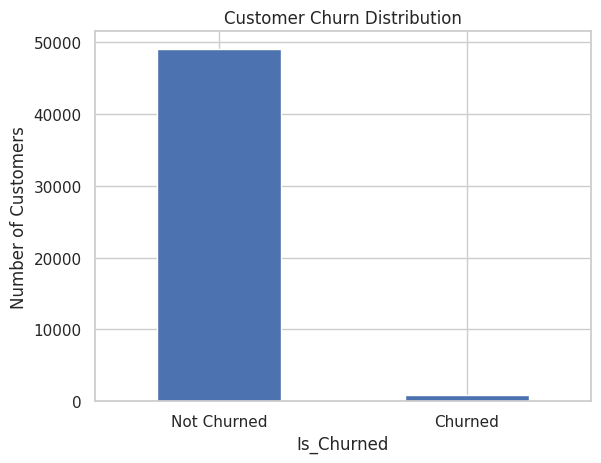

In [46]:
labels = {0: 'Not Churned', 1: 'Churned'}

df_clean['Is_Churned'].value_counts().sort_index().rename(labels).plot(
    kind='bar', title='Customer Churn Distribution'
)

plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

### 11.2 Feature Adoption by Churn Status

**Business Question:** Do churned and non-churned customers differ in product feature usage?

**Purpose:** Compare average feature adoption between the two customer groups.

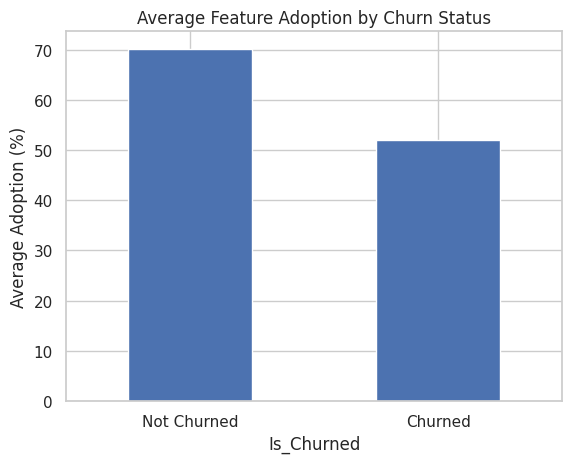

In [47]:
df_clean.groupby('Is_Churned')['Feature_Adoption_Rate'].mean().rename(
    index=labels
).plot(kind='bar', title='Average Feature Adoption by Churn Status')

plt.ylabel('Average Adoption (%)')
plt.xticks(rotation=0)
plt.show()

### 11.3 Support Tickets by Churn Status

**Business Question:** Do churned customers raise more support tickets?

**Purpose:** Compare average support activity between churned and non-churned customers.

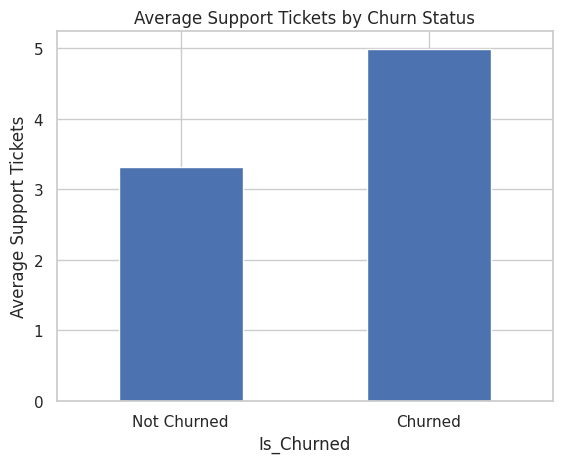

In [48]:
df_clean.groupby('Is_Churned')['Support_Tickets_30d'].mean().rename(
    index=labels
).plot(kind='bar', title='Average Support Tickets by Churn Status')

plt.ylabel('Average Support Tickets')
plt.xticks(rotation=0)
plt.show()

### 11.4 Monthly Recurring Revenue by Churn Status

**Business Question:** How does average monthly recurring revenue differ between churned and non-churned customers?

**Purpose:** Compare the average revenue contribution of both customer groups.

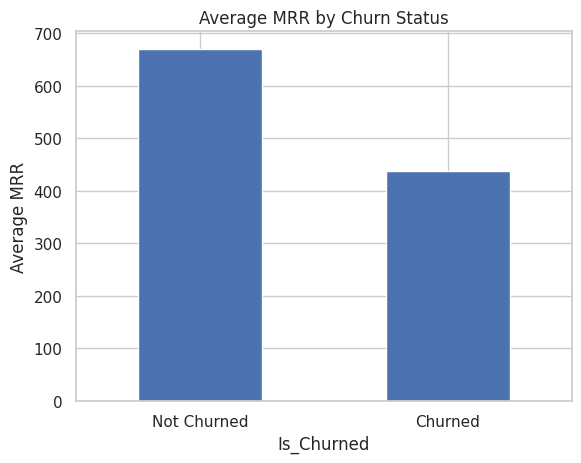

In [49]:
df_clean.groupby('Is_Churned')['Monthly_Recurring_Revenue'].mean().rename(
    index=labels
).plot(kind='bar', title='Average MRR by Churn Status')

plt.ylabel('Average MRR')
plt.xticks(rotation=0)
plt.show()

## 12. Advanced Exploratory Data Analysis

**Purpose:** Explore deeper relationships between customer behaviour, payment status, revenue and churn to identify potential retention risks.

This section uses advanced charts to investigate customer risk patterns and relationships between important variables.

### 12.1 Churn Rate by Risk Score

**Business Question:** Do customers with higher predicted churn risk actually have higher churn rates?

**Purpose:** Compare the predicted risk categories with actual customer churn.

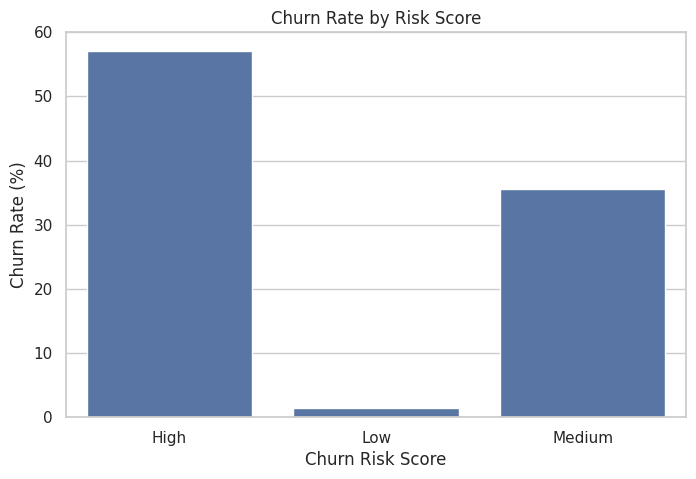

In [50]:
risk_churn = df_clean.groupby('Churn_Risk_Score')['Is_Churned'].mean().mul(100)

plt.figure(figsize=(8, 5))
sns.barplot(x=risk_churn.index, y=risk_churn.values)

plt.title('Churn Rate by Risk Score')
plt.xlabel('Churn Risk Score')
plt.ylabel('Churn Rate (%)')
plt.show()

### 12.2 Churn Rate by Plan Tier and Payment Status

**Business Question:** Does churn vary depending on the combination of subscription plan and payment status?

**Purpose:** Identify plan and payment combinations that may need greater customer retention attention.

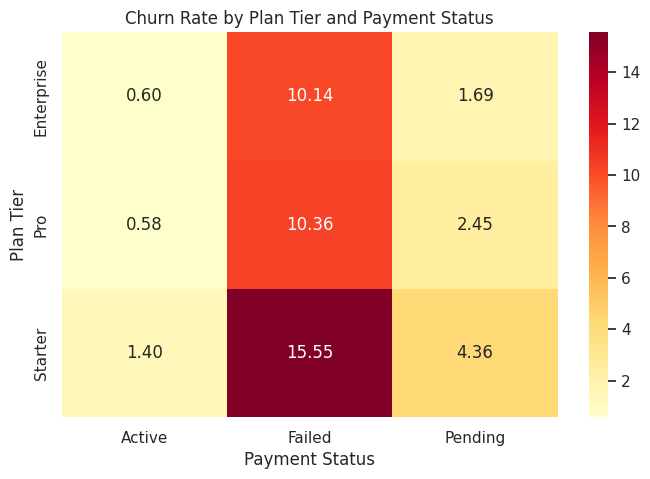

In [51]:
# Calculate churn percentage for each combination
plan_payment = df_clean.pivot_table(
    values='Is_Churned',
    index='Plan_Tier',
    columns='Payment_Status',
    aggfunc='mean'
) * 100

# Create heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(plan_payment, annot=True, fmt='.2f', cmap='YlOrRd')

plt.title('Churn Rate by Plan Tier and Payment Status')
plt.xlabel('Payment Status')
plt.ylabel('Plan Tier')
plt.show()

### 12.3 Revenue Distribution by Churn Status

**Business Question:** How does the distribution of monthly recurring revenue differ between churned and non-churned customers?

**Purpose:** Compare revenue patterns and identify differences in customer revenue contribution.

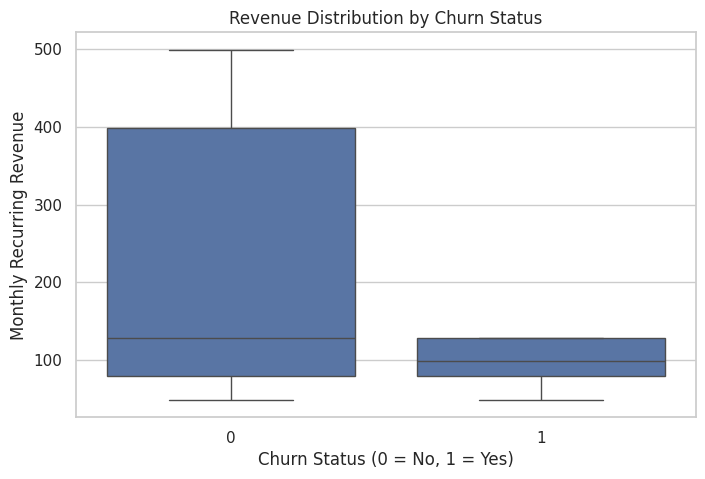

In [52]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='Is_Churned',
    y='Monthly_Recurring_Revenue',
    showfliers=False
)

plt.title('Revenue Distribution by Churn Status')
plt.xlabel('Churn Status (0 = No, 1 = Yes)')
plt.ylabel('Monthly Recurring Revenue')
plt.show()

### 12.4 Customer Tenure Distribution

**Business Question:** How does customer tenure differ between churned and non-churned customers?

**Purpose:** Understand customer retention patterns over time.

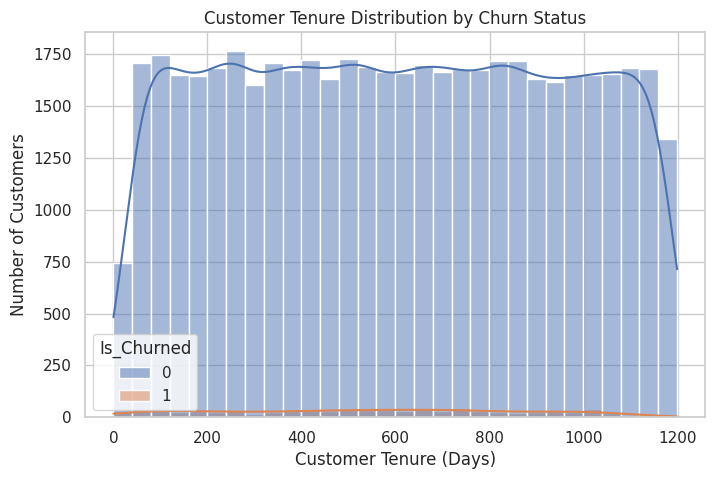

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='Customer_Tenure_Days',
    hue='Is_Churned',
    bins=30,
    kde=True
)

plt.title('Customer Tenure Distribution by Churn Status')
plt.xlabel('Customer Tenure (Days)')
plt.ylabel('Number of Customers')
plt.show()

### 12.5 Feature Adoption vs Support Tickets

**Business Question:** Is there a relationship between feature adoption and customer support activity?

**Purpose:** Explore whether customers with different feature adoption levels also experience different levels of support activity.

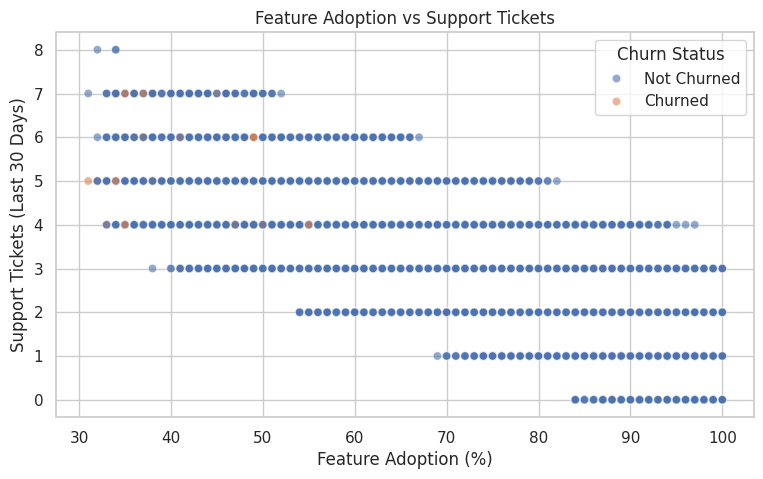

In [53]:
plot_df = df_clean.sample(
    n=min(5000, len(df_clean)),
    random_state=42
).copy()

plot_df['Churn Status'] = plot_df['Is_Churned'].map(
    {0: 'Not Churned', 1: 'Churned'}
)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=plot_df,
    x='Feature_Adoption_Rate',
    y='Support_Tickets_30d',
    hue='Churn Status',
    alpha=0.6
)

plt.title('Feature Adoption vs Support Tickets')
plt.xlabel('Feature Adoption (%)')
plt.ylabel('Support Tickets (Last 30 Days)')
plt.show()

## 13. Correlation Analysis

**Business Question:** Which numerical variables have stronger relationships with customer churn?

**Purpose:** Examine relationships between numerical customer attributes, including revenue, feature adoption, support tickets, tenure and churn status.

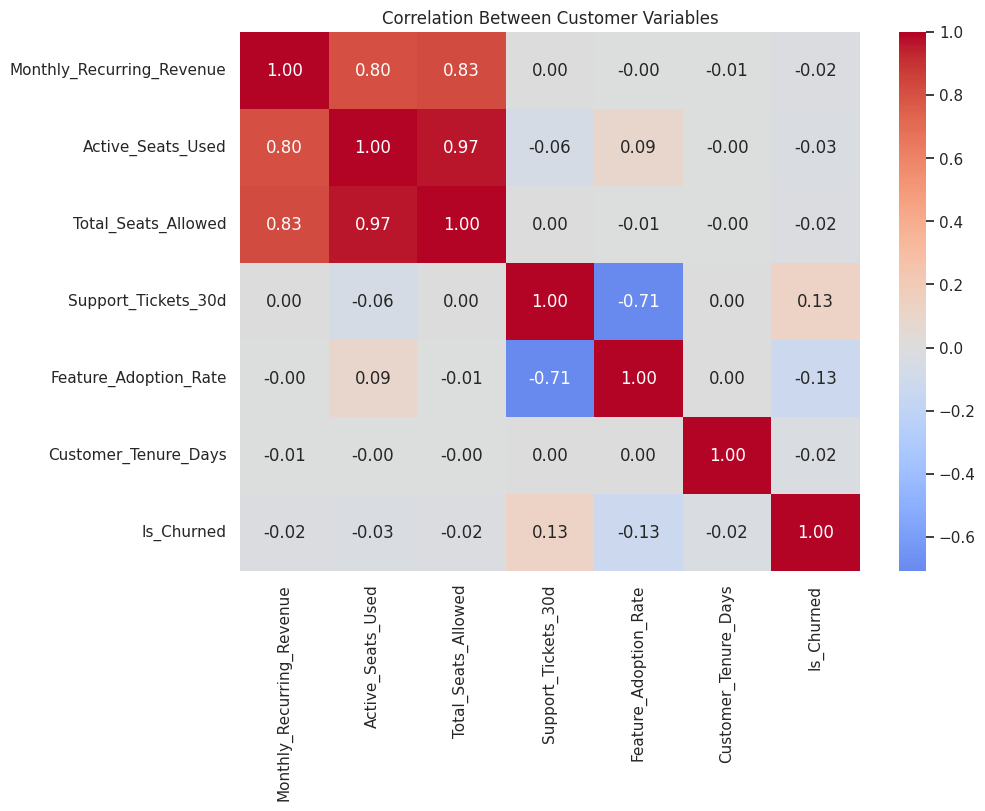

In [54]:
# Select numerical columns
numeric_df = df_clean[
    ['Monthly_Recurring_Revenue',
     'Active_Seats_Used',
     'Total_Seats_Allowed',
     'Support_Tickets_30d',
     'Feature_Adoption_Rate',
     'Customer_Tenure_Days',
     'Is_Churned']
]

# Create correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Between Customer Variables')
plt.show()

In [55]:
# Rank numerical relationships with churn
churn_corr = numeric_df.corr()['Is_Churned'].drop('Is_Churned')

print("Correlation with Churn:")
print(churn_corr.sort_values())

Correlation with Churn:
Feature_Adoption_Rate       -0.130876
Active_Seats_Used           -0.025927
Customer_Tenure_Days        -0.022862
Total_Seats_Allowed         -0.019630
Monthly_Recurring_Revenue   -0.018895
Support_Tickets_30d          0.128952
Name: Is_Churned, dtype: float64


### Correlation Findings
- Feature Adoption Rate has the strongest negative correlation with churn (-0.131).
- Support Tickets have the strongest positive correlation with churn (+0.129).
- Other numerical variables show very weak correlations with churn.

### Business Interpretation
Feature adoption and support activity show the clearest numerical relationships with churn in this analysis. The business should investigate whether improving product engagement and resolving customer support issues can improve retention.

However, all observed correlations are weak, so these variables should not be used alone to predict customer churn.

## 14. Final Business Insights and Recommendations

### Key Business Insights

1. **Payment Risk:** Customers with failed payments have a higher churn percentage (13.47%).
2. **Plan Tier:** Starter plan customers have higher churn (2.15%) than Pro and Enterprise customers (1.07%).
3. **Feature Adoption:** Churned customers have lower average feature adoption (51.91%) than non-churned customers (70.12%).
4. **Customer Support:** Churned customers have more average support tickets (4.99) than non-churned customers (3.32).
5. **Revenue:** Churned customers have lower average MRR (437.94) than non-churned customers (669.71).

### Business Recommendations

- Introduce payment reminders and payment recovery processes.
- Improve onboarding for Starter plan customers.
- Encourage customers to explore more product features.
- Investigate common customer support problems.
- Identify at-risk customers early and provide retention support.

## 15. Project Conclusion

This project analysed 50,000 synthetic SaaS customer records using Excel, MySQL and Python. The analysis explored customer distribution, payment status, feature adoption, churn patterns, revenue and customer behaviour.

The findings highlight payment failures, lower feature adoption and higher support activity as important areas for further investigation and customer retention improvement.

**Dataset Limitation:** The dataset is synthetic. These findings demonstrate an analytical approach and should not be treated as verified real-world business results.